<a href="https://colab.research.google.com/github/Ericatuitui/MSSP607/blob/main/Assignments/Assignment1/Assignment_1_Huarui_Yao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
from google.colab import userdata
import os
github_token = userdata.get('Git_Key')
owner = 'Ericatuitui'
repository = 'MSSP607'
clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'
!git clone {clone_url}

fatal: destination path 'MSSP607' already exists and is not an empty directory.


In [13]:
import pandas as pd
df = pd.read_csv('/content/MSSP607/Assignments/Assignment1/data_academic_performance.csv')
df.head(n=10)

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2
5,SB11201210007568,F,Complete professional education,Complete professional education,Independent,Executive,Stratum 6,It is not classified by the SISBEN,Three,NaN,...,32,97,36,170,154,63,4,3,4,2
6,SB11201210007598,M,Complete professional education,Complete professional education,Small entrepreneur,Executive,Stratum 5,It is not classified by the SISBEN,Four,NaN,...,50,92,53,187,152,59,3,3,2,2
7,SB11201210007615,F,Incomplete Secundary,Complete Secundary,Entrepreneur,Independent professional,Stratum 6,It is not classified by the SISBEN,Five,NaN,...,94,97,98,188,200,99,5,4,4,4
8,SB11201210010208,M,Complete Secundary,Complete professional education,Independent,Operator,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,43,3,19,177,133,28,2,2,3,2
9,SB11201210013577,M,Incomplete technical or technological,Incomplete technical or technological,Independent,Home,Stratum 2,Level 2,Four,NaN,...,22,83,1,112,126,18,1,1,4,2


In [14]:
quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "unique_values": df.nunique()
})
quality_summary

,dtype,missing,missing_pct,unique_values
COD_S11,object,0,0.0,12411
GENDER,object,0,0.0,2
EDU_FATHER,object,0,0.0,12
EDU_MOTHER,object,0,0.0,12
OCC_FATHER,object,0,0.0,12
OCC_MOTHER,object,0,0.0,12
STRATUM,object,0,0.0,7
SISBEN,object,0,0.0,6
PEOPLE_HOUSE,object,0,0.0,13
Unnamed: 9,float64,12411,100.0,0


Question 1 Does parental education influence outcomes, and if so, how much?

In [15]:
df.groupby("EDU_FATHER")[["MAT_S11", "CR_S11", "CC_S11",
                            "BIO_S11", "ENG_S11"]].mean()

,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11
EDU_FATHER,,,,,
0,59.179028,56.946292,57.199488,60.153453,55.383632
Complete Secundary,62.282800,59.427014,59.297573,62.071403,58.040802
Complete primary,60.660194,57.983010,58.552184,60.791262,54.888350
Complete professional education,67.013594,62.490053,62.370690,66.208886,66.833886
Complete technique or technology,64.881072,61.294807,61.268007,64.365159,62.198492
Incomplete Professional Education,66.268235,62.378824,62.157647,65.689412,65.190588
Incomplete Secundary,61.271311,58.709441,58.662695,61.274060,56.535289
Incomplete primary,61.250340,58.523810,58.782313,61.331973,55.945578
Incomplete technical or technological,63.389892,60.606498,59.985560,63.718412,60.263538


In [16]:
df.groupby("EDU_MOTHER")[["MAT_S11", "CR_S11", "CC_S11",
                            "BIO_S11", "ENG_S11"]].mean()

,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11
EDU_MOTHER,,,,,
0,59.126289,57.074742,57.059278,59.979381,55.605670
Complete Secundary,62.186735,59.241468,59.324855,62.005795,57.697682
Complete primary,60.504909,57.767181,58.395512,61.151473,55.029453
Complete professional education,67.440994,62.783916,62.579928,66.614253,67.685518
Complete technique or technology,64.557191,61.272910,61.197324,64.035452,62.270903
Incomplete Professional Education,65.990040,62.796813,62.256972,65.155378,64.296813
Incomplete Secundary,60.949811,58.340909,58.518939,61.020833,56.048295
Incomplete primary,60.824399,58.225508,58.258780,61.243993,54.951941
Incomplete technical or technological,64.038123,61.492669,60.756598,63.870968,61.134897


In [17]:
df.groupby("EDU_FATHER")["G_SC"].mean()

,G_SC
EDU_FATHER,
0,155.076726
Complete Secundary,158.785790
Complete primary,155.195388
Complete professional education,167.765915
Complete technique or technology,164.033501
Incomplete Professional Education,166.917647
Incomplete Secundary,156.535289
Incomplete primary,155.729252
Incomplete technical or technological,162.101083


In [18]:
df.groupby("EDU_MOTHER")["G_SC"].mean()

,G_SC
EDU_MOTHER,
0,154.930412
Complete Secundary,158.470702
Complete primary,155.336606
Complete professional education,168.845374
Complete technique or technology,163.242140
Incomplete Professional Education,166.685259
Incomplete Secundary,155.672348
Incomplete primary,154.853974
Incomplete technical or technological,161.879765


In [19]:
df["S11_AVG"] = df[["MAT_S11", "CR_S11", "CC_S11",
                    "BIO_S11", "ENG_S11"]].mean(axis=1)

In [20]:
df[["S11_AVG", "G_SC"]].describe()

,S11_AVG,G_SC
count,12411.000000,12411.000000
mean,62.311192,162.710499
std,9.642924,23.112479
min,35.800000,37.000000
25%,55.200000,147.000000
50%,61.800000,163.000000
75%,69.000000,179.000000
max,95.600000,247.000000


Text(0.5, 0.98, "S11 Average Score by Parents' Education Level")

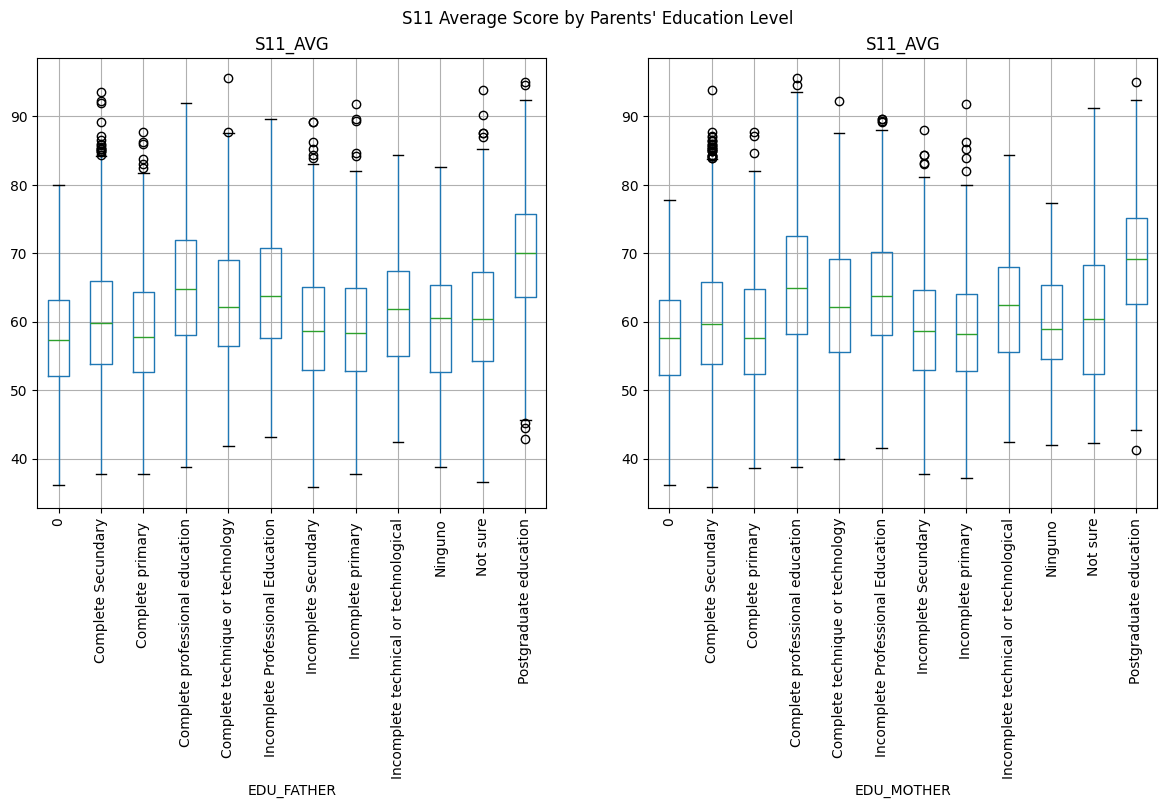

In [21]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df.boxplot(column="S11_AVG", by="EDU_FATHER", ax=axes[0], rot=90)
df.boxplot(column="S11_AVG", by="EDU_MOTHER", ax=axes[1], rot=90)
plt.suptitle("S11 Average Score by Parents' Education Level")

Text(0.5, 0.98, "Global Score by Parents' Education Level")

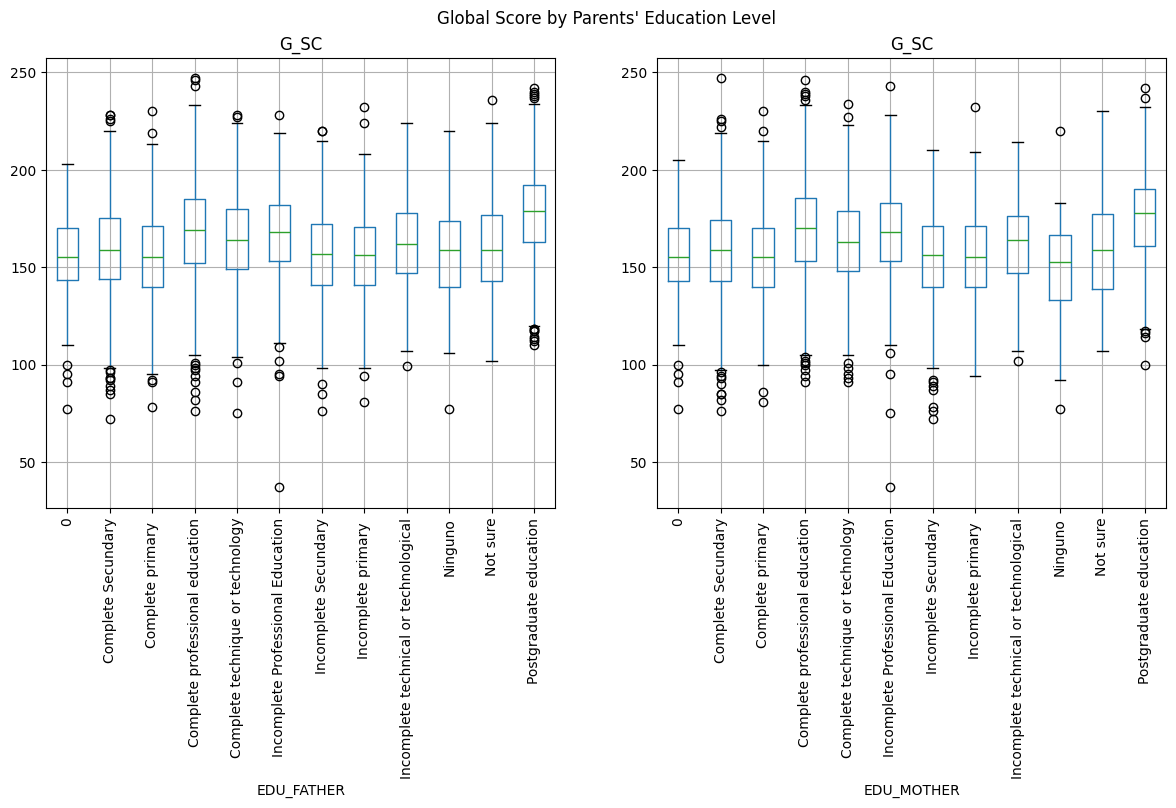

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df.boxplot(column="G_SC", by="EDU_FATHER", ax=axes[0], rot=90)
df.boxplot(column="G_SC", by="EDU_MOTHER", ax=axes[1], rot=90)

plt.suptitle("Global Score by Parents' Education Level")

In [23]:
father_s11 = df.groupby("EDU_FATHER")["S11_AVG"].mean()

father_s11_change = (
    (father_s11.max() - father_s11.min())
    / father_s11.min()
) * 100

father_s11_change

20.38792503916408

In [24]:
mother_s11 = df.groupby("EDU_MOTHER")["S11_AVG"].mean()

mother_s11_change = (
    (mother_s11.max() - mother_s11.min())
    / mother_s11.min()
) * 100

mother_s11_change

18.62122164910034

In [25]:
s11_change = (father_s11_change + mother_s11_change) / 2

s11_change

19.50457334413221

In [26]:
father_pro = df.groupby("EDU_FATHER")["G_SC"].mean()

father_pro_change = (
    (father_pro.max() - father_pro.min())
    / father_pro.min()
) * 100

father_pro_change

14.127540366755973

In [27]:
mother_pro = df.groupby("EDU_MOTHER")["G_SC"].mean()

mother_pro_change = (
    (mother_pro.max() - mother_pro.min())
    / mother_pro.min()
) * 100

mother_pro_change

17.321315616791424

In [28]:
pro_change = (father_pro_change + mother_pro_change) / 2

pro_change

15.724427991773698

Question 2 Which groups/stratum performs best? Are there differences between groups/stratums? Explain your analysis.

In [29]:
stratum_mean = df.groupby("STRATUM")[["S11_AVG", "G_SC"]].mean()
stratum_mean

,S11_AVG,G_SC
STRATUM,,
0,54.942857,154.000000
Stratum 1,57.570158,152.352838
Stratum 2,59.945098,158.199305
Stratum 3,62.691125,163.815328
Stratum 4,66.853485,172.002535
Stratum 5,70.109637,177.387046
Stratum 6,72.478908,181.511166


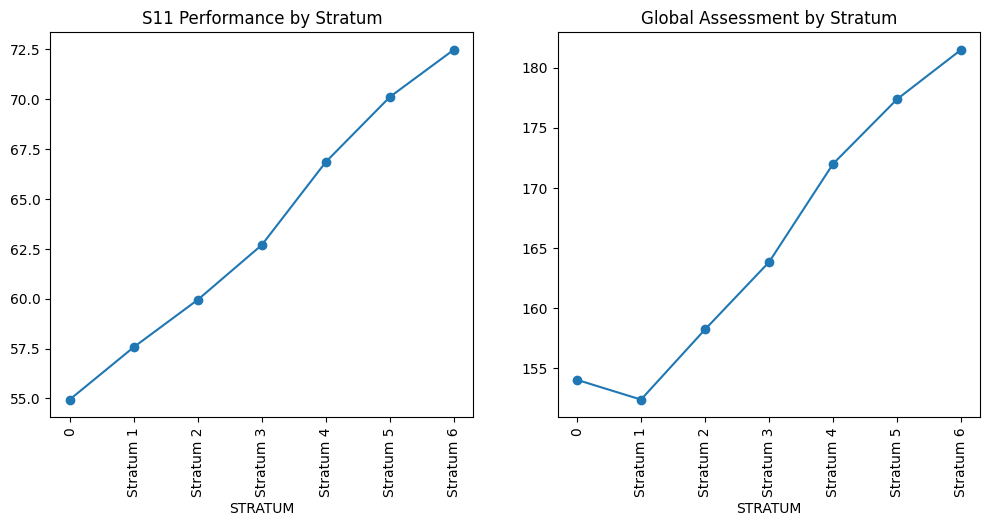

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stratum_mean["S11_AVG"].plot(
    ax=axes[0],
    marker="o",
    title="S11 Performance by Stratum",
    rot=90
)

stratum_mean["G_SC"].plot(
    ax=axes[1],
    marker="o",
    title="Global Assessment by Stratum",
    rot=90
)

plt.show()

question 3 How does each gender perform in the global assessment?

In [31]:
df["GENDER"].value_counts()

,count
GENDER,
M,7368
F,5043


In [32]:
gender_mean = df.groupby("GENDER")["G_SC"].mean()
gender_mean

,G_SC
GENDER,
F,161.278207
M,163.690825


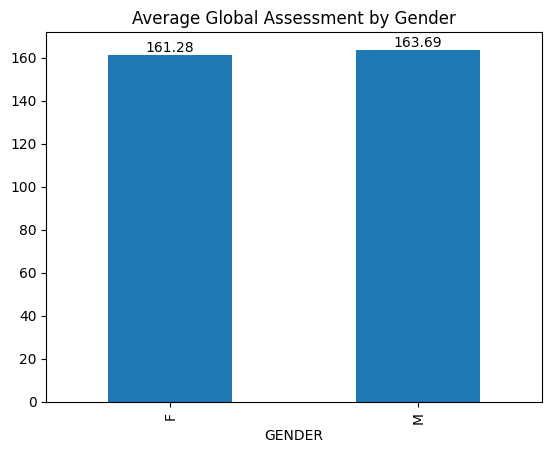

In [33]:
ax = gender_mean.plot(
    kind="bar",
    title="Average Global Assessment by Gender"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

My question：Are students who perform well in one S11 subject also likely to perform well in other S11 subjects?

In [34]:
subjects = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11"]

In [35]:
corr = df[subjects].corr()
corr

,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11
MAT_S11,1.000000,0.609894,0.594732,0.763082,0.594903
CR_S11,0.609894,1.000000,0.731217,0.661651,0.581045
CC_S11,0.594732,0.731217,1.000000,0.657576,0.548531
BIO_S11,0.763082,0.661651,0.657576,1.000000,0.593273
ENG_S11,0.594903,0.581045,0.548531,0.593273,1.000000


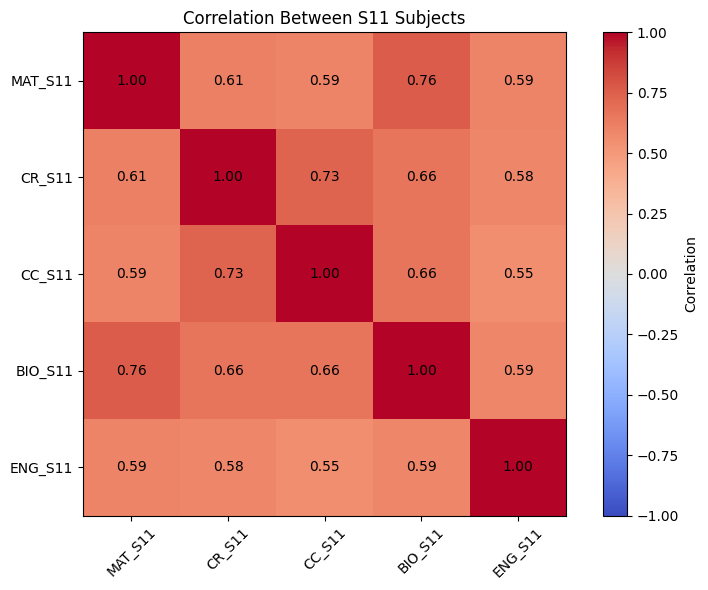

In [36]:
plt.figure(figsize=(8, 6))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(subjects)), subjects, rotation=45)
plt.yticks(range(len(subjects)), subjects)

for i in range(len(subjects)):
    for j in range(len(subjects)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Between S11 Subjects")
plt.tight_layout()
plt.show()

My question: Do students with higher overall S11 performance tend to achieve higher global assessment scores later?

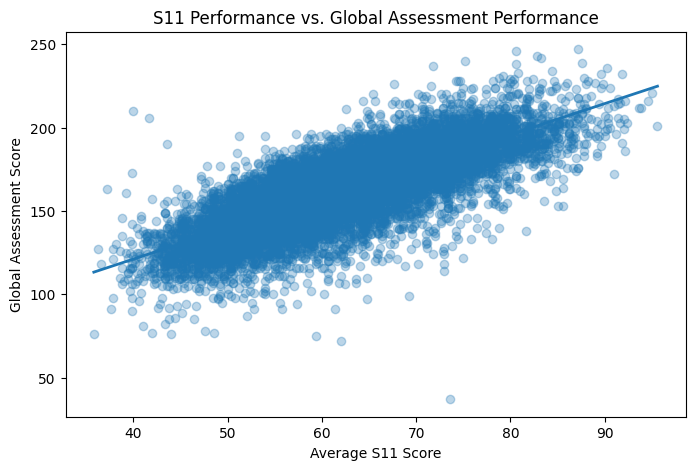

Correlation: 0.7783523531074771


In [37]:
import numpy as np
import matplotlib.pyplot as plt
x = df["S11_AVG"]
y = df["G_SC"]

slope, intercept = np.polyfit(x, y, 1)

line_x = np.linspace(x.min(), x.max(), 100)
line_y = slope * line_x + intercept

plt.figure(figsize=(8, 5))

plt.scatter(x, y, alpha=0.3)
plt.plot(line_x, line_y, linewidth=2)

plt.xlabel("Average S11 Score")
plt.ylabel("Global Assessment Score")
plt.title("S11 Performance vs. Global Assessment Performance")

plt.show()

print("Correlation:", x.corr(y))